In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("transactions_TP2.csv")
print(df.head())
print("Nombre de lignes et colonnes:",df.shape)
print(df.dtypes)

  id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure  \
0      OP02438    C10278     5396.62             90.0         6.0     11   
1      OP00157    C10019      438.41             55.0         2.0     22   
2      OP01987    C10604     2846.79              NaN         1.0     10   
3      OP00207    C10330      914.14            127.0         4.0      7   
4      OP00738    C10380      228.23            110.0         4.0      5   

         canal    appareil             region international resultat_enquete  \
0     site_web      mobile     Marrakech-Safi           non    aucune_fraude   
1  application      mobile        Souss-Massa           non    aucune_fraude   
2    telephone  ordinateur  Casablanca-Settat           non    aucune_fraude   
3  application      mobile  Casablanca-Settat           non    aucune_fraude   
4  application    terminal  Casablanca-Settat           non    aucune_fraude   

   fraude  
0       0  
1       0  
2       0  
3       0  
4 

In [2]:
df=pd.read_csv("transactions_TP2.csv")

In [3]:
missing =pd.DataFrame({"Nombre":df.isnull().sum(),"Pourcentage":df.isnull().mean() * 100})
print(missing.sort_values(by="Pourcentage",ascending=False))

                  Nombre  Pourcentage
canal                159     5.221675
anciennete_mois      137     4.499179
appareil             122     4.006568
montant_dh           110     3.612479
region               103     3.382594
nb_ops_24h            53     1.740558
id_operation           0     0.000000
id_client              0     0.000000
heure                  0     0.000000
international          0     0.000000
resultat_enquete       0     0.000000
fraude                 0     0.000000


In [4]:
print("Doublons:",df.duplicated(subset="id_operation").sum())
df= df.drop_duplicates(subset="id_operation")
print("Lignes restantes:",len(df))

Doublons: 45
Lignes restantes: 3000


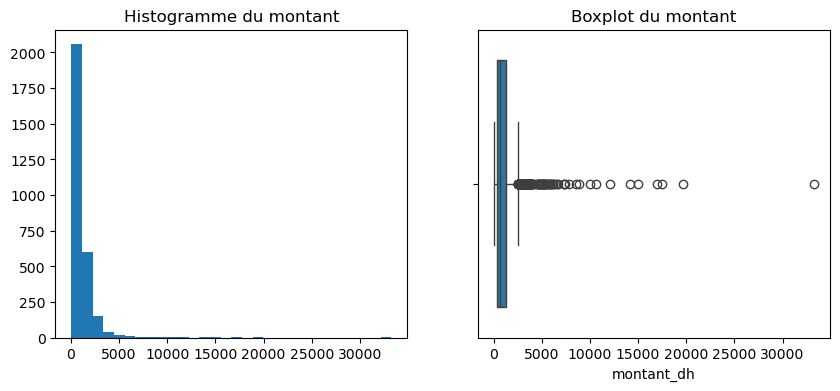

In [5]:
plt.figure(figsize =(10,4))
plt.subplot(1,2,1)
plt.hist(df["montant_dh"].dropna(),bins=30)
plt.title("Histogramme du montant")
plt.subplot(1,2,2)
sns.boxplot(x=df["montant_dh"])
plt.title("Boxplot du montant")
plt.show()

fraude
0    2742
1     258
Name: count, dtype: int64
fraude
0    91.4
1     8.6
Name: proportion, dtype: float64


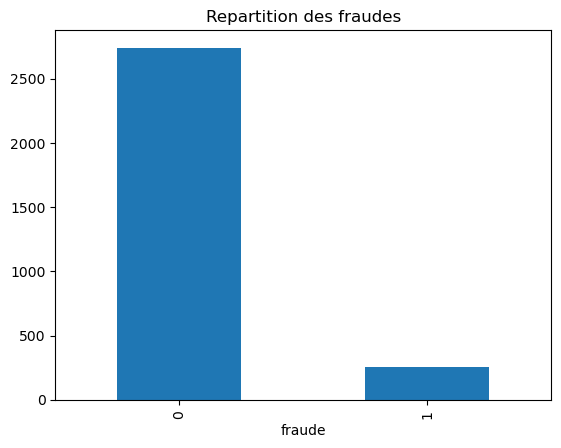

In [6]:
print(df["fraude"].value_counts())
print(df["fraude"].value_counts(normalize=True)*100)
df["fraude"].value_counts().plot(kind="bar",title="Repartition des fraudes")
plt.show()

In [7]:
print(df[["id_operation","id_client","resultat_enquete"]].head())

  id_operation id_client resultat_enquete
0      OP02438    C10278    aucune_fraude
1      OP00157    C10019    aucune_fraude
2      OP01987    C10604    aucune_fraude
3      OP00207    C10330    aucune_fraude
4      OP00738    C10380    aucune_fraude


In [8]:
x=df.drop(columns=["id_operation","id_client","resultat_enquete","fraude"])
y=df["fraude"]
print(x.head())
print(y.head())

   montant_dh  anciennete_mois  nb_ops_24h  heure        canal    appareil  \
0     5396.62             90.0         6.0     11     site_web      mobile   
1      438.41             55.0         2.0     22  application      mobile   
2     2846.79              NaN         1.0     10    telephone  ordinateur   
3      914.14            127.0         4.0      7  application      mobile   
4      228.23            110.0         4.0      5  application    terminal   

              region international  
0     Marrakech-Safi           non  
1        Souss-Massa           non  
2  Casablanca-Settat           non  
3  Casablanca-Settat           non  
4  Casablanca-Settat           non  
0    0
1    0
2    0
3    0
4    0
Name: fraude, dtype: int64


In [9]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)
print(x_train.shape)
print(x_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(2400, 8)
(600, 8)
fraude
0    2194
1     206
Name: count, dtype: int64
fraude
0    548
1     52
Name: count, dtype: int64


In [10]:
num_cols = [ "montant_dh","anciennete_mois","nb_ops_24h","heure" ]
cat_cols=["canal","appareil","region","international"]
print(num_cols)
print(cat_cols)
print(x_train[num_cols].head())

['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
['canal', 'appareil', 'region', 'international']
      montant_dh  anciennete_mois  nb_ops_24h  heure
384       419.53             53.0         3.0     16
2064      533.01            115.0         5.0     23
625       477.87             83.0         3.0     23
267      2518.08             10.0         0.0      5
2306      394.74             97.0         2.0     12


In [11]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
num_pipeline = Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())])
num_pipeline.fit(x_train[num_cols])
print("Medianes:",num_pipeline.named_steps["imputer"].statistics_)
print("Moyennes:",num_pipeline.named_steps["scaler"].mean_)

Medianes: [710.79  87.     3.    11.  ]
Moyennes: [1020.672925     87.48333333    2.72083333   11.47      ]


In [12]:
from sklearn.preprocessing import OneHotEncoder
cat_pipeline= Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                        ("encoder",OneHotEncoder(handle_unknown="ignore"
                                                ))
                       ])
cat_pipeline.fit(x_train[cat_cols])

,steps,"[('imputer', ...), ('encoder', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,categories,'auto'


In [13]:
from sklearn.compose import ColumnTransformer
preprocessor = ColumnTransformer([
    ("num", num_pipeline,num_cols),
    ("cat",cat_pipeline,cat_cols)
])
x_train_transformed = preprocessor.fit_transform(x_train)
x_test_transformed= preprocessor.transform(x_test)
print(x_train_transformed.shape)
print(x_test_transformed.shape)


(2400, 18)
(600, 18)


In [14]:
from sklearn.preprocessing import RobustScaler
standard= StandardScaler()
robust= RobustScaler()
a=np.array([[100],[200],[300],[500],[10000]])
print("StandardScaler:")
print(standard.fit_transform(a))
print("RobustScaler:")
print(robust.fit_transform(a))

StandardScaler:
[[-0.54467229]
 [-0.5189802 ]
 [-0.49328811]
 [-0.44190393]
 [ 1.99884452]]
RobustScaler:
[[-0.66666667]
 [-0.33333333]
 [ 0.        ]
 [ 0.66666667]
 [32.33333333]]


In [15]:
Q1= x_train["montant_dh"].quantile(0.25)
Q3=x_train["montant_dh"].quantile(0.75)
IQR=Q3-Q1
print("Q1=",Q1)
print("Q3=",Q3)
print("IQR=",IQR)

Q1= 393.095
Q3= 1249.8775
IQR= 856.7825


In [16]:
born_inf= Q1-1.5*IQR
born_sup=Q3+1.5*IQR
outliers= x_train[
    (x_train["montant_dh"] < born_inf)|
    (x_train["montant_dh"]> born_sup)
    ]
print("Borne inferieure:",born_inf)
print("Borne superieure:",born_sup)
print("Nombre de valeurs extremes:",len(outliers))

Borne inferieure: -892.0787499999999
Borne superieure: 2535.05125
Nombre de valeurs extremes: 146


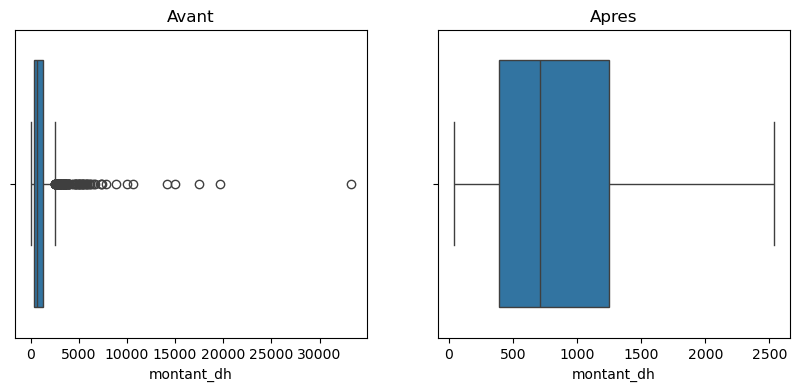

In [17]:
x_train_limite= x_train.copy()
x_train_limite["montant_dh"] = (x_train_limite["montant_dh"].clip(
    lower=born_inf,
    upper=born_sup
)
                               )
fig,axes=plt.subplots(1,2,figsize=(10,4))
sns.boxplot(x=x_train["montant_dh"],
            ax=axes[0])
axes[0].set_title("Avant")
sns.boxplot(x=x_train_limite["montant_dh"],ax=axes[1])
axes[1].set_title("Apres")
plt.show()

In [18]:
from sklearn.preprocessing import MinMaxScaler
scalers = {
    "MinMax": MinMaxScaler(),
    "Standard":StandardScaler(),
    "Robust":RobustScaler()
}
for nom,scaler in scalers.items():
    scaler.fit(x_train[["montant_dh"]])
    resultat = scaler.transform(
    x_test[["montant_dh"]]
    )
    print(nom,resultat[:5].flatten())

MinMax [0.02283333 0.03334204 0.00669849 0.00936657 0.01248164]
Standard [-0.17536899  0.08317633 -0.57233403 -0.50669123 -0.43005122]
Robust [ 0.0988699   0.50662799 -0.52719331 -0.42366645 -0.30279563]


In [19]:
montants=np.array([
    [200],
    [500],
    [1000],
    [20000]
])
for nom, scaler in scalers.items():
    scaler.fit(x_train[["montant_dh"]])
    valeurs= scaler.transform(montants)
    print("\n",nom)
    print(valeurs)


 MinMax
[[0.00492077]
 [0.01394473]
 [0.02898467]
 [0.60050227]]

 Standard
[[-0.61607123]
 [-0.39405499]
 [-0.02402791]
 [14.03700085]]

 Robust
[[-0.59617231]
 [-0.2460251 ]
 [ 0.33755358]
 [22.5135434 ]]


C:\Users\Kival\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
C:\Users\Kival\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\Kival\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RobustScaler was fitted with feature names
  warnings.warn(


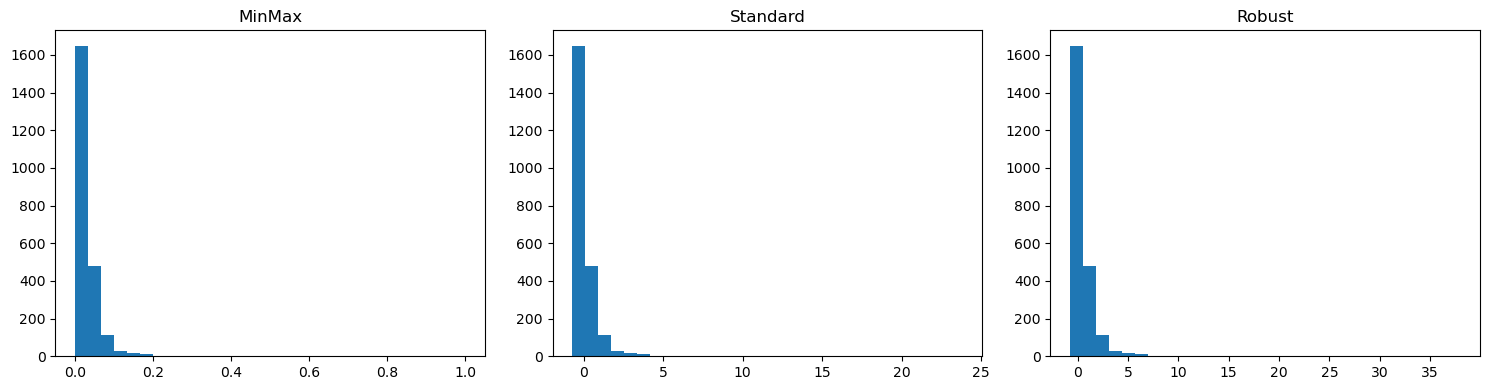

In [20]:
fig,axes = plt.subplots(1,3,figsize=(15,4))
for ax,(nom,scaler)in zip(axes,scalers.items()):
    scaler.fit(x_train[["montant_dh"]])
    valeurs =scaler.transform(x_train[["montant_dh"]])
    ax.hist(valeurs.flatten(),bins=30)
    ax.set_title(nom)

plt.tight_layout()
plt.show()

In [21]:
from sklearn.preprocessing import MinMaxScaler

scaler=MinMaxScaler()

a=np.array([[10],[20],[30]])

scaler.fit(a)

nouvelle_valeur=scaler.transform([[40]])

print(nouvelle_valeur)

[[1.5]]


In [22]:
print(y_train.value_counts())

print("Proportion:")
print(y_train.value_counts(normalize=True)*100)

fraude
0    2194
1     206
Name: count, dtype: int64
Proportion:
fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64


In [23]:
from imblearn.over_sampling import RandomOverSampler
ros=RandomOverSampler(random_state=42)
x_over,y_over=ros.fit_resample(x_train,y_train)

print("Avant:")
print(y_train.value_counts())

print("Apres:")
print(y_over.value_counts())

Avant:
fraude
0    2194
1     206
Name: count, dtype: int64
Apres:
fraude
0    2194
1    2194
Name: count, dtype: int64


In [24]:
from imblearn.under_sampling import RandomUnderSampler
rus= RandomUnderSampler(random_state=42)

x_under,y_under=rus.fit_resample(x_train,y_train)
print(y_under.value_counts())

fraude
0    206
1    206
Name: count, dtype: int64


In [25]:
from imblearn.over_sampling import SMOTE
exemple= np.array([
    [1,2],
    [2,3],
    [3,4],
    [8,9]
])
print("Valeur reelle:",exemple[0])
print("Exemple synthetique possible:",[1.5,2,5])

Valeur reelle: [1 2]
Exemple synthetique possible: [1.5, 2, 5]


In [26]:
print("Donnees initiales:")
print(y_train.value_counts())
print("\nApres surechantillonnage:")
print(y_over.value_counts())
print("\nApres sous-echantillonnage:")
print(y_under.value_counts())

Donnees initiales:
fraude
0    2194
1     206
Name: count, dtype: int64

Apres surechantillonnage:
fraude
0    2194
1    2194
Name: count, dtype: int64

Apres sous-echantillonnage:
fraude
0    206
1    206
Name: count, dtype: int64


In [27]:
from sklearn.preprocessing import RobustScaler
num_final=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",RobustScaler())
                   ])
cat_final= Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                     ("encoder",OneHotEncoder(handle_unknown="ignore"))
                    ])
preprocessor_final=ColumnTransformer([("num",num_final,num_cols),("cat",cat_final,cat_cols)
                                     ])
                                    

In [28]:
x_train_final=preprocessor_final.fit_transform(x_train)
x_test_final=preprocessor_final.transform(x_test)
print("Train:",x_train_final.shape)
print("Test:",x_test_final.shape)

Train: (2400, 18)
Test: (600, 18)


In [29]:
nouveau=x_test.iloc[[0]].copy()
nouveau["canal"]="nouveau_canal"
resultat=preprocessor_final.transform(nouveau)
print(resultat)

[[ 0.10375406 -0.29761905 -1.          0.30769231  0.          0.
   0.          0.          0.          1.          0.          0.
   0.          1.          0.          0.          0.          1.        ]]


In [30]:
import joblib
joblib.dump(preprocessor_final,"preprocesseur.pkl")
precharge=joblib.load("preprocesseur.pkl")
resultat1=preprocessor_final.transform(x_test.iloc[:5])
                                      
resultat2=precharge.transform(x_test.iloc[:5])
print(np.allclose(resultat1.toarray()if hasattr(resultat1,"toarray")else resultat1,
                  resultat2.toarray()if hasattr(resultat2,"toarray")else resultat2
                 ))a


True


In [33]:
print("Moyenne:",df["montant_dh"].mean())
print("Mediane:",df["montant_dh"].median())

Moyenne: 1028.35945731075
Mediane: 708.66


In [34]:
from sklearn.impute import SimpleImputer
num_imputer=SimpleImputer(strategy="median")
x_train[num_cols]= num_imputer.fit_transform(x_train[num_cols])
cat_imputer=SimpleImputer(strategy="most_frequent")
x_train[cat_cols]=cat_imputer.fit_transform(x_train[cat_cols])

In [35]:
from imblearn.over_sampling import SMOTENC
cat_indices=[x_train.columns.get_loc(col)
             for col in cat_cols]
smotenc = SMOTENC(categorical_features=cat_indices,random_state=42)
x_smote,y_smote=smotenc.fit_resample(x_train,y_train)
print(y_smote.value_counts())

fraude
0    2194
1    2194
Name: count, dtype: int64
